# 01 · Two-asset comparison: volatility and correlation (BTC vs ETH)

**Goal:** download daily candles for two pairs from one exchange (default: BTC/USDT and ETH/USDT on
**Binance spot**, 2018-01-01 UTC to the last *closed* daily candle) and compare them: how volatile is
each one, how much do they move together, and does that relationship change over time?

**Data source:** public spot market data via `ccxt` (no API key). Candle timestamps are the
**open time** of each daily candle, interpreted as **UTC**.

**Returns:** we use **simple** daily returns (`pct_change`). Log returns come later (Phase 2).

### How to use this notebook

1. Write your **predictions** in the next cell *before* running anything.
2. Run the cells **one at a time, top to bottom** (or *Restart & Run All*).
3. Compare the results with your predictions in the last section.

### How to reuse it as a template

- All parameters live in the **settings** cell (section 1): exchange, the two pairs, start date,
  rolling windows, portfolio weight and the thresholds for "extreme" days. Every code cell reads
  them, so changing them is enough to rerun the analysis on another pair or exchange.
- The prose and the *Results vs predictions* table describe the **default run**
  (BTC/USDT vs ETH/USDT on Binance spot). If you change the parameters, update them too.
- Data is cached per exchange in `data/<exchange>_spot_1d/` (gitignored). Delete that folder to
  download fresh data.
- For a new person: copy the notebook, clear the *Answer* lines in the predictions cell and the
  *Results* table, and start again from step 1.


## Predictions (written before running)

Fill in each answer and a confidence from 1 (pure guess) to 5 (very sure).

1. Is each candle's timestamp in seconds or in milliseconds?
   - Answer: In miliseconds
   - Confidence (1-5): 5
2. Which one is more volatile (std of daily returns), BTC or ETH? Rough size of each std (%)?
   - Answer: ETH 6%
   - Confidence (1-5): 1
3. Correlation of daily returns over the whole sample? *(Pre-test answer: 0.34, confidence 1.)*
   - Answer:0
   - Confidence (1-5): 2
4. Does the 90-day rolling correlation ever drop below 0.5? When?
   - Answer: Yes, when it's holidays xd
   - Confidence (1-5): 1
5. Largest daily drop of each asset: approximate size and date?
   - Answer: 15%, 2020 november
   - Confidence (1-5): 1

## 1. Imports and settings

All parameters live here: which exchange, which two pairs, the start date, the rolling windows, the portfolio weight and the thresholds for extreme days. In the code, `A` and `B` are the first and second pair. The download and
cleaning code lives in `src/data/ohlcv.py` (with tests in `tests/test_ohlcv.py`), so the
notebook stays short and we can reuse the same functions later with other exchanges.
We locate the repo root (the folder with `CLAUDE.md`) so imports and the `data/` folder work
whether the notebook runs from the repo root or from `notebooks/`.

In [1]:
import sys
from pathlib import Path

import ccxt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data.ohlcv import align_closes, check_daily_candles, fetch_daily_ohlcv

# ---- Parameters: change these to reuse the notebook ----
EXCHANGE_ID = "binance"            # Binance **spot** market (ccxt's default for "binance")
SYMBOLS = ["BTC/USDT", "ETH/USDT"] # exactly two pairs: asset A and asset B
START_UTC = "2018-01-01"           # first candle we ask for, 00:00 UTC
ROLLING_DAYS = 90                  # main window for the rolling correlation (days)
ROLLING_DAYS_SHORT = 30            # shorter window, compared in section 10.2 (days)
WEIGHT_A = 0.5                     # weight of asset A in the two-asset portfolio (10.1); B gets 1 - WEIGHT_A
TAIL_THRESHOLDS_PCT = [5, 10, 15, 20]  # absolute daily moves (in %) counted as "extreme" (10.3)

# ---- Derived names and plot style (no need to change) ----
assert len(SYMBOLS) == 2, "this notebook compares exactly two pairs"
A, B = SYMBOLS
VENUE = f"{EXCHANGE_ID} spot"      # used in titles: every price belongs to one exchange
LINE_COLORS = ["#2a78d6", "#eb6834"]  # blue / orange, colorblind-safe pair
COLORS = dict(zip(SYMBOLS, LINE_COLORS))
GRAY = "#52514e"                   # reference lines

CACHE_DIR = REPO_ROOT / "data" / f"{EXCHANGE_ID}_spot_1d"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
print("ccxt version:", ccxt.__version__)
print("Cache folder:", CACHE_DIR.relative_to(REPO_ROOT).as_posix())  # relative: no local user path

ccxt version: 4.5.92
Cache folder: data/binance_spot_1d


## 2. Download (or load from cache) the daily candles

For each pair we call `fetch_daily_ohlcv`, which:

1. **Paginates.** Binance returns at most 1,000 candles per request, and we need ~3,000.
   We ask for candles starting at `since` (Unix **milliseconds**), then ask again starting at the
   last timestamp we received **+ 1 ms**, until nothing new comes back. `enableRateLimit=True`
   makes ccxt wait between calls so we stay under Binance's request limits. No API key is
   needed: candles are public market data.
2. **Converts timestamps** with `unit="ms"` to UTC dates. Each timestamp is the candle's
   **open time** (00:00 UTC).
3. **Drops the candle that is still forming** (see below).
4. **Checks the data** (duplicates, order, prices > 0, missing days).

The result is saved as Parquet in `data/` (git ignores that folder). Like in notebook 00,
the cache **freezes** the sample: re-runs analyze exactly the same days. The file name includes
the start date (e.g. `BTCUSDT_1d_from_2018-01-01.parquet`), so a different `START_UTC` downloads
again instead of silently reusing a cache that starts on another day. The download time is saved
inside the file and printed when it is loaded. To get fresh data, delete
`data/<exchange>_spot_1d/` and run again.

### Why we drop today's candle

A daily candle covers 00:00 to 24:00 UTC. While the day is still running, its "close" is just
the latest trade, and its high, low and volume can still change. If we kept it, the last row would
mix final values with temporary ones, and any calculation on it (a return, a correlation) would use
a number that **was not final yet**. In a backtest that is **look-ahead bias**: the strategy would
use information it could not have had at that point. So a candle that opens at time T is kept only
if T + 1 day <= the moment we downloaded.

In [2]:
exchange = getattr(ccxt, EXCHANGE_ID)({"enableRateLimit": True})
start_utc = pd.Timestamp(START_UTC, tz="UTC")

frames = {}
for symbol in SYMBOLS:
    # The start date is part of the file name, so changing START_UTC never reuses an old cache.
    cache_file = CACHE_DIR / f"{symbol.replace('/', '')}_1d_from_{START_UTC}.parquet"
    if cache_file.exists():
        frames[symbol] = pd.read_parquet(cache_file)
        downloaded_at = frames[symbol].attrs.get("downloaded_at_utc", "unknown")
        print(f"{symbol}: loaded from cache ({cache_file.name}), downloaded at {downloaded_at}")
    else:
        now_utc = pd.Timestamp.now(tz="UTC")
        frames[symbol], _ = fetch_daily_ohlcv(exchange, symbol, START_UTC, now_utc=now_utc)
        frames[symbol].attrs["downloaded_at_utc"] = f"{now_utc:%Y-%m-%d %H:%M} UTC"  # stored in the file
        frames[symbol].to_parquet(cache_file)
        print(f"{symbol}: downloaded at {now_utc:%Y-%m-%d %H:%M} UTC -> {len(frames[symbol])} closed candles")

    first = frames[symbol].index.min()
    assert first >= start_utc, f"{symbol}: data starts before START_UTC"
    if first > start_utc:  # e.g. the pair was listed on the exchange after START_UTC
        print(f"   note: first candle is {first:%Y-%m-%d}, later than START_UTC = {START_UTC}")

frames[A].tail(3)

BTC/USDT: loaded from cache (BTCUSDT_1d_from_2018-01-01.parquet), downloaded at 2026-11-14 00:30 UTC
ETH/USDT: loaded from cache (ETHUSDT_1d_from_2018-01-01.parquet), downloaded at 2026-11-14 00:30 UTC


,timestamp_ms,open,high,low,close,volume
open_time_utc,,,,,,
2026-11-11 00:00:00+00:00,1794355200000,73796.06,74811.45,73209.12,74015.19,16145.87951
2026-11-12 00:00:00+00:00,1794441600000,74015.20,74217.49,71113.06,71460.00,15228.24045
2026-11-13 00:00:00+00:00,1794528000000,71460.00,71514.01,67568.00,68314.00,29648.75209


## 3. Validate the data

We re-run the checks on what we actually analyze (also when it comes from the cache).
`check_daily_candles` **stops the notebook** (raises an error) if it finds duplicate dates,
dates out of order, candles that do not open at 00:00 UTC, or prices <= 0. The `assert` lines make
each check explicit: if one is false, the notebook stops right there.

**Missing days.** `check_daily_candles` only *reports* them, because an exchange outage is a real
event and the caller should decide what to do. Here we **also stop the notebook** if there is any:
if a day were missing, the next `pct_change` would compare closes **two days apart** but label the
result as a one-day return, which silently inflates the volatility. If this ever stops you: print
the missing dates, check the exchange's status history for those days, and decide explicitly (for
example, drop the returns that span the gap) and write that decision down here.


In [3]:
for symbol, df in frames.items():
    report = check_daily_candles(df)
    assert not df.index.duplicated().any(), "duplicate dates"
    assert df.index.is_monotonic_increasing, "dates not in increasing order"
    assert (df[["open", "high", "low", "close"]] > 0).all().all(), "price <= 0"
    assert str(df.index.tz) == "UTC", "index is not UTC"
    print(f"{symbol}: {report['candles']} candles, "
          f"{report['first']:%Y-%m-%d} to {report['last']:%Y-%m-%d} (UTC), "
          f"duplicates: {report['duplicates']}, missing days: {len(report['missing_days'])}")
    for day in report["missing_days"]:
        print(f"   missing: {day:%Y-%m-%d}")
    # A missing day would make the next pct_change span 2 days while looking like 1 (see above).
    assert not report["missing_days"], f"{symbol}: missing days, decide how to handle them first"

print("ALL CHECKS: PASS")

BTC/USDT: 3239 candles, 2018-01-01 to 2026-11-13 (UTC), duplicates: 0, missing days: 0
ETH/USDT: 3239 candles, 2018-01-01 to 2026-11-13 (UTC), duplicates: 0, missing days: 0
ALL CHECKS: PASS


## 4. Align both series by date

We put both closing prices in one table with one row per UTC date. Only dates that exist for
**both** pairs are kept, and we print how many dates were dropped, so nothing disappears silently. We also check that consecutive dates are exactly one day
apart, so each return in the next section really covers one day.

In [4]:
closes, dropped = align_closes(frames)
for symbol, days in dropped.items():
    print(f"{symbol}: dates dropped during alignment: {len(days)}")
assert closes.index.equals(frames[A].index.intersection(frames[B].index))
assert closes.notna().all().all()
# Consecutive rows must be exactly 1 day apart, so every return below is a 1-day return
assert (closes.index.to_series().diff().dropna() == pd.Timedelta(days=1)).all(), "gap between dates"
print(f"Aligned table: {len(closes)} days, "
      f"{closes.index.min():%Y-%m-%d} to {closes.index.max():%Y-%m-%d} (UTC)")
closes.head()

BTC/USDT: dates dropped during alignment: 0
ETH/USDT: dates dropped during alignment: 0
Aligned table: 3239 days, 2018-01-01 to 2026-11-13 (UTC)


,BTC/USDT,ETH/USDT
open_time_utc,,
2018-01-01 00:00:00+00:00,13380.00,754.99
2018-01-02 00:00:00+00:00,14675.11,855.28
2018-01-03 00:00:00+00:00,14919.51,934.03
2018-01-04 00:00:00+00:00,15059.54,940.00
2018-01-05 00:00:00+00:00,16960.39,959.30


## 5. Daily returns

A **simple daily return** is how much the price changed from one close to the next, as a fraction:
`(close_today - close_yesterday) / close_yesterday`. `pct_change()` computes it for every row;
we multiply by 100 to read it in %. Look at the first row before we continue.

In [5]:
returns_with_first_row = closes.pct_change() * 100
print(returns_with_first_row.head(3).round(2))

returns = returns_with_first_row.dropna()
print(f"\n{len(returns)} daily returns per asset")

                           BTC/USDT  ETH/USDT
open_time_utc                                
2018-01-01 00:00:00+00:00       NaN       NaN
2018-01-02 00:00:00+00:00      9.68     13.28
2018-01-03 00:00:00+00:00      1.67      9.21

3238 daily returns per asset


## 6. Volatility: standard deviation of daily returns

The **standard deviation** (std) measures how spread out the daily returns are around their
average: a bigger std means bigger typical daily moves, so more volatility.

**Annualized volatility.** To compare with numbers quoted "per year", we multiply the daily std by
the square root of the number of trading days in a year. If daily returns are independent, their
variances add up over the year, so the std grows with the **square root** of time.
Stock markets trade about **252** days a year (weekdays minus holidays), which is why you will often
see √252. **Crypto trades every day, 24/7**, weekends included, so our year has **365** daily
returns and we use √365. Using 252 here would understate the yearly volatility.

In [6]:
daily_std = returns.std()
vol = pd.DataFrame({
    "daily std (%)": daily_std,
    "annualized std (%) = daily x sqrt(365)": daily_std * np.sqrt(365),
})
vol.round(2)

,daily std (%),annualized std (%) = daily x sqrt(365)
BTC/USDT,3.35,63.95
ETH/USDT,4.41,84.24


## 7. Correlation over the whole sample

The **correlation** of two return series is a number between -1 and +1:
+1 means they always move in the same direction (and proportionally), 0 means no linear
relationship, -1 means they always move in opposite directions. We compute the usual (Pearson)
correlation of the daily returns, using every day in the sample.

In [7]:
full_corr = returns[A].corr(returns[B])
print(f"Correlation of daily returns, {returns.index.min():%Y-%m-%d} to "
      f"{returns.index.max():%Y-%m-%d}: {full_corr:.2f}")

Correlation of daily returns, 2018-01-02 to 2026-11-13: 0.82


## 8. Rolling 90-day correlation

One number for the whole sample can hide changes over time. The **rolling correlation** computes
the correlation over a moving window: the value on day *t* uses only the **90 daily returns
ending on day t** (days t-89 to t). It never uses day t+1 or later, so there is **no look-ahead**:
on any day, the value could have been computed with the data available at that day's close.
The first 89 days have no value because the window is not full yet.

Below we also group consecutive days with correlation under 0.5 into *episodes*.

In [8]:
rolling_corr = returns[A].rolling(ROLLING_DAYS).corr(returns[B]).dropna()
print(f"Rolling {ROLLING_DAYS}-day correlation: "
      f"min {rolling_corr.min():.2f} on {rolling_corr.idxmin():%Y-%m-%d}, "
      f"max {rolling_corr.max():.2f} on {rolling_corr.idxmax():%Y-%m-%d}")

# A new episode id starts every time the series crosses the 0.5 line.
below = rolling_corr < 0.5
episode_id = (below != below.shift()).cumsum()
episodes = pd.DataFrame([
    {"start (UTC)": s.index.min().date(), "end (UTC)": s.index.max().date(),
     "days": len(s), "min corr": round(s.min(), 2)}
    for _, s in rolling_corr[below].groupby(episode_id[below])
])
print(f"Days below 0.5: {below.sum()} of {len(rolling_corr)}")
episodes

Rolling 90-day correlation: min 0.55 on 2021-01-04, max 0.96 on 2023-01-11
Days below 0.5: 0 of 3149


""


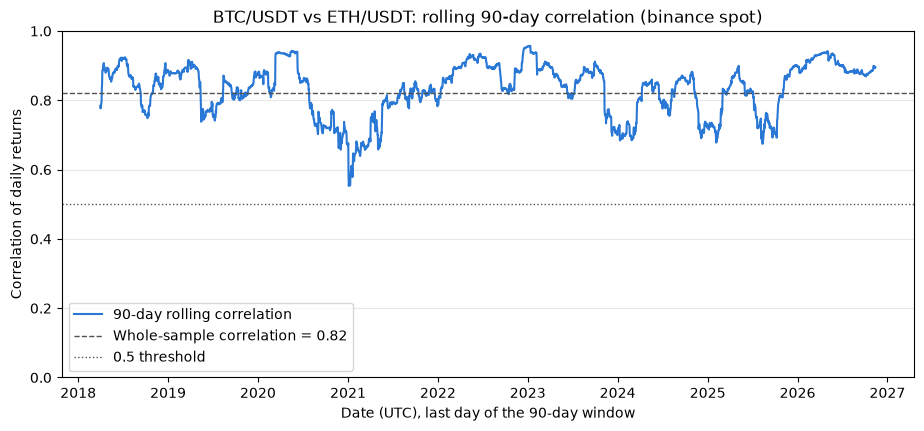

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(rolling_corr.index, rolling_corr, color=LINE_COLORS[0], linewidth=1.5,
        label=f"{ROLLING_DAYS}-day rolling correlation")
ax.axhline(full_corr, color=GRAY, linestyle="--", linewidth=1,
           label=f"Whole-sample correlation = {full_corr:.2f}")
ax.axhline(0.5, color=GRAY, linestyle=":", linewidth=1, label="0.5 threshold")
ax.set_ylim(min(0, rolling_corr.min() - 0.05), 1)
ax.set_xlabel(f"Date (UTC), last day of the {ROLLING_DAYS}-day window")
ax.set_ylabel("Correlation of daily returns")
ax.set_title(f"{A} vs {B}: rolling {ROLLING_DAYS}-day correlation ({VENUE})")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower left")
plt.show()

## 9. The 10 biggest daily moves of each asset

We sort the days by the **absolute** value of the return (size of the move, ignoring direction)
and keep the top 10, showing the real sign. Each date is the UTC day of the candle whose close is
compared with the previous day's close.

In [10]:
top_moves = {}
for symbol in SYMBOLS:
    r = returns[symbol]
    top = r.loc[r.abs().sort_values(ascending=False).index[:10]]
    top_moves[symbol] = pd.DataFrame(
        {"date (UTC)": top.index.date, "return (%)": top.round(2).values}, index=range(1, 11)
    )
pd.concat(top_moves, axis=1)

BTC/USDT               ETH/USDT           
    date (UTC) return (%)  date (UTC) return (%)
1   2020-03-12     -39.50  2020-03-12     -44.60
2   2021-02-08      19.54  2021-05-19     -27.74
3   2018-01-16     -19.50  2021-05-24      26.33
4   2019-04-02      17.20  2021-01-03      26.30
5   2019-10-25      16.76  2020-03-13      24.34
6   2020-03-13      16.22  2025-05-08      21.88
7   2022-06-13     -15.38  2018-01-16     -21.32
8   2018-02-05     -15.21  2020-04-06      20.07
9   2022-02-28      14.49  2018-09-05     -19.90
10  2021-05-19     -14.38  2021-01-21     -19.32

In [11]:
worst = pd.DataFrame({
    "largest daily drop (%)": returns.min().round(2),
    "date (UTC)": returns.idxmin().dt.date,
})
worst

,largest daily drop (%),date (UTC)
BTC/USDT,-39.5,2020-03-12
ETH/USDT,-44.6,2020-03-12


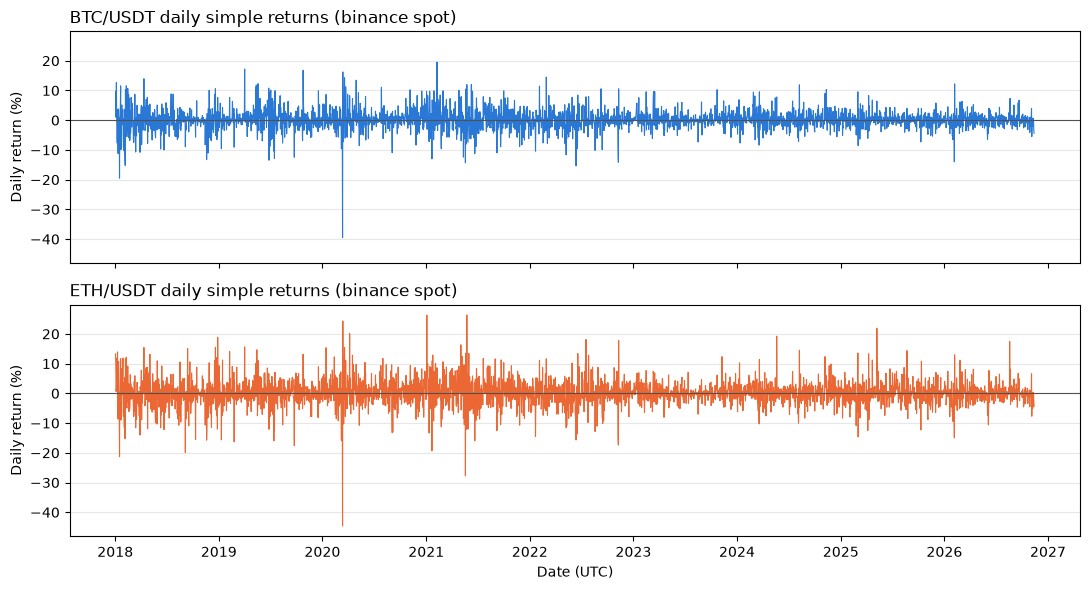

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, sharey=True)
for ax, symbol in zip(axes, SYMBOLS):
    ax.plot(returns.index, returns[symbol], color=COLORS[symbol], linewidth=0.8)
    ax.axhline(0, color=GRAY, linewidth=0.8)
    ax.set_ylabel("Daily return (%)")
    ax.set_title(f"{symbol} daily simple returns ({VENUE})", loc="left")
    ax.grid(axis="y", alpha=0.3)
axes[-1].set_xlabel("Date (UTC)")
fig.tight_layout()
plt.show()

## 10. Extensions

Three small modifications built on the results above. Before running each one, write a one-line
prediction in its cell (answer + confidence from 1 to 5).

### 10.1 Two-asset portfolio (default: 50% BTC / 50% ETH)

**Question:** if we hold both assets, is the portfolio's volatility below the calmer asset, between
the two, or above the more volatile one?

**Prediction (written before running):** *(answer)* — confidence _/5

**How:** the daily return of the portfolio is the weighted sum of the two daily returns,
`WEIGHT_A * ret_A + (1 - WEIGHT_A) * ret_B`, computed day by day. Then we compare the standard
deviation (std) of three options: 100% A, 100% B and the portfolio.

**Hidden assumptions:** using the same weights every day means the portfolio is **rebalanced daily**
back to the target weights, and that rebalancing is **free**. This is not the same as buying 50/50
once and holding: without rebalancing, the weights drift as prices move. In real trading every
rebalance pays fees and spread; those costs mostly lower the portfolio's **return** and barely
change its **volatility**, which is what we measure here. So read this as an idealized, cost-free
calculation of risk, not a tradable result.

In [13]:
# Daily return of a portfolio that holds WEIGHT_A of A and the rest in B (rebalanced daily, no costs)
portfolio_returns = WEIGHT_A * returns[A] + (1 - WEIGHT_A) * returns[B]
portfolio_name = f"{WEIGHT_A:.0%} {A} / {1 - WEIGHT_A:.0%} {B}"

stds = pd.Series({
    f"100% {A}": returns[A].std(),
    f"100% {B}": returns[B].std(),
    portfolio_name: portfolio_returns.std(),
}, name="daily std (%)")
stds.round(2)

100% BTC/USDT                  3.35
100% ETH/USDT                  4.41
50% BTC/USDT / 50% ETH/USDT    3.70
Name: daily std (%), dtype: float64

#### What if the correlation were different?

We cannot change the correlation of the real data, but the std of a two-asset portfolio can be
computed from just five numbers: the two weights, the two stds and the correlation:

$$\sigma_p^2 = w_A^2\,\sigma_A^2 + w_B^2\,\sigma_B^2 + 2\,w_A\,w_B\,\rho\,\sigma_A\,\sigma_B$$

- We work with **variances** (std squared) because variances add up; stds do not.
- $w_A^2\sigma_A^2$ is the risk asset A brings on its own. The weight is squared: holding half of A
  makes its moves half as big, which is a quarter of the variance.
- $2\,w_A w_B\,\rho\,\sigma_A\sigma_B$ is the **interaction term**. With $\rho = 1$ the two assets
  fall together and the risks pile up; with $\rho = 0$ this term disappears; with a negative $\rho$
  it *subtracts* risk. This is where diversification comes from.

**Sanity check:** with the real correlation (`full_corr`) the formula must give exactly the same
std as the portfolio computed from the data in the previous cell.

**Prediction (written before running):** with a correlation of 0.3 the portfolio std would be about
*(answer)* % — confidence _/5

In [14]:
def portfolio_std(w_a, std_a, std_b, corr):
    """Std of a two-asset portfolio from the weight of A, both stds and their correlation."""
    w_b = 1 - w_a
    variance = (w_a**2 * std_a**2
                + w_b**2 * std_b**2
                + 2 * w_a * w_b * corr * std_a * std_b)
    return np.sqrt(variance)

std_a = returns[A].std()
std_b = returns[B].std()

# The formula with the real correlation must reproduce the std measured on the data
assert np.isclose(portfolio_std(WEIGHT_A, std_a, std_b, full_corr), portfolio_returns.std())

for corr in [1.0, full_corr, 0.3, 0.0]:
    print(f"correlation {corr:.2f} -> {portfolio_name} daily std = "
          f"{portfolio_std(WEIGHT_A, std_a, std_b, corr):.2f}%")

correlation 1.00 -> 50% BTC/USDT / 50% ETH/USDT daily std = 3.88%
correlation 0.82 -> 50% BTC/USDT / 50% ETH/USDT daily std = 3.70%
correlation 0.30 -> 50% BTC/USDT / 50% ETH/USDT daily std = 3.14%
correlation 0.00 -> 50% BTC/USDT / 50% ETH/USDT daily std = 2.77%


### 10.2 Shorter rolling window (default: 30 days vs 90 days)

**Question:** with a shorter window, does the rolling correlation ever drop below 0.5? Does the line
look smoother or noisier?

**Prediction (written before running):** *(answer)* — confidence _/5

**How:** same rolling correlation as in section 8, but each value uses only the last
`ROLLING_DAYS_SHORT` daily returns. It still uses **only past data** (no look-ahead). With fewer days
per value, a few unusual days weigh much more. To measure "noisier" with a number instead of by eye,
we compute the std of the **day-to-day change** of each line: a bigger value means a jumpier line.

**Statistical noise:** a correlation measured on only 30 days is itself uncertain. A rough rule for
its standard error is $(1-\rho^2)/\sqrt{n}$: with $\rho \approx 0.8$ and $n = 30$ that is about
0.07, and it gets wider as $\rho$ falls. So part of the dips of the short line can be pure chance.
We do not attribute the dips to any cause here.

The y-axis lower limit is set from whichever line goes lower, so neither line is cut off.

,30-day window,90-day window
min,0.355768,0.553106
date of min (UTC),2021-01-09,2021-01-04
days below 0.5,24,0
days with a value,3209,3149
std of day-to-day change,0.022931,0.007508


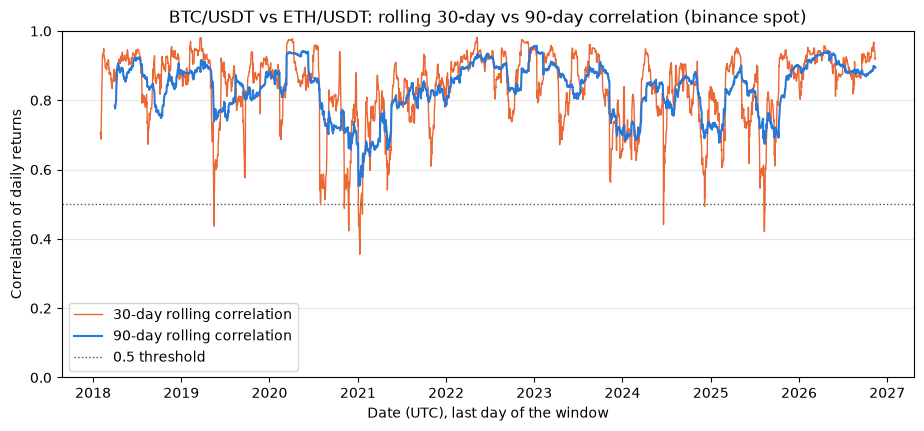

In [15]:
rolling_corr_short = returns[A].rolling(ROLLING_DAYS_SHORT).corr(returns[B]).dropna()

summary = pd.DataFrame({
    f"{days}-day window": {
        "min": s.min(),
        "date of min (UTC)": s.idxmin().date(),
        "days below 0.5": int((s < 0.5).sum()),
        "days with a value": len(s),
        "std of day-to-day change": s.diff().std(),
    }
    for days, s in [(ROLLING_DAYS_SHORT, rolling_corr_short), (ROLLING_DAYS, rolling_corr)]
})
display(summary)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(rolling_corr_short.index, rolling_corr_short, color=LINE_COLORS[1], linewidth=1,
        label=f"{ROLLING_DAYS_SHORT}-day rolling correlation")
ax.plot(rolling_corr.index, rolling_corr, color=LINE_COLORS[0], linewidth=1.5,
        label=f"{ROLLING_DAYS}-day rolling correlation")
ax.axhline(0.5, color=GRAY, linestyle=":", linewidth=1, label="0.5 threshold")
ax.set_ylim(min(0, rolling_corr_short.min() - 0.05, rolling_corr.min() - 0.05), 1)
ax.set_xlabel("Date (UTC), last day of the window")
ax.set_ylabel("Correlation of daily returns")
ax.set_title(f"{A} vs {B}: rolling {ROLLING_DAYS_SHORT}-day vs {ROLLING_DAYS}-day correlation ({VENUE})")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower left")
plt.show()

### 10.3 Extreme days and "fat tails"

**Question:** on what % of days does each asset move more than 5% (up or down)? Do crypto returns
look like a bell curve (normal distribution)?

**Prediction (written before running):** A about _% of days, B about _% — confidence _/5

**How:**
- `returns.abs()` drops the sign (-7% becomes 7%), so "more than X% up **or** down" is a single
  comparison. The threshold is in % (e.g. `5`, not `0.05`) because `returns` is already in %.
- The mean of a True/False column is the fraction of True days (True counts as 1, False as 0).
- For comparison, we compute how many days a **bell curve with the same std** would predict, using
  `erfc` (the two-sided tail of the normal distribution, assuming an average daily return of ~0).
  *z* is the threshold measured in stds.

**How to read it:** a distribution with **fat tails** has *more* very quiet days and *more* very
extreme days than a bell curve with the same std, and *fewer* medium-sized days. So the ratio
real / bell can be **below 1** for a small threshold (about 1 to 1.5 std) and grow very fast for
large ones. Look at the whole table, not only the first row. The last line checks the other side:
the share of quiet days (within ±1 std), where a bell curve predicts 68.3%.

**Small counts:** a ratio built on very few real days (fewer than about 5) is mostly noise. For
example, a single 20% day can give a ratio in the hundreds of thousands. Read those rows only as
"it happened, while a bell curve says it should practically never happen", not as a precise number.

In [16]:
from math import erfc, sqrt


def normal_tail_pct(threshold_pct, std_pct):
    """% of days a normal distribution (mean 0, given std) moves more than threshold, up or down."""
    return erfc(threshold_pct / std_pct / sqrt(2)) * 100


n_days = len(returns)
rows = []
for symbol in SYMBOLS:
    std = returns[symbol].std()
    for threshold in TAIL_THRESHOLDS_PCT:
        real_pct = (returns[symbol].abs() > threshold).mean() * 100
        bell_pct = normal_tail_pct(threshold, std)
        rows.append({
            "asset": symbol,
            "|move| >": f"{threshold}%",
            "z (threshold / std)": round(threshold / std, 1),
            "real % of days": round(real_pct, 2),
            "real days": round(real_pct / 100 * n_days),
            "bell-curve days (expected)": round(bell_pct / 100 * n_days, 2),
            "real / bell": round(real_pct / bell_pct, 1),
        })
display(pd.DataFrame(rows).set_index(["asset", "|move| >"]))

for symbol in SYMBOLS:
    quiet_pct = (returns[symbol].abs() <= returns[symbol].std()).mean() * 100
    print(f"{symbol}: {quiet_pct:.1f}% of days within ±1 std (bell curve: 68.3%)")

z (threshold / std)  real % of days  real days  \
asset    |move| >                                                   
BTC/USDT 5%                        1.5           10.90        353   
         10%                       3.0            1.91         62   
         15%                       4.5            0.25          8   
         20%                       6.0            0.03          1   
ETH/USDT 5%                        1.1           18.31        593   
         10%                       2.3            4.20        136   
         15%                       3.4            1.05         34   
         20%                       4.5            0.25          8   

                   bell-curve days (expected)  real / bell  
asset    |move| >                                           
BTC/USDT 5%                            438.01          0.8  
         10%                             9.11          6.8  
         15%                             0.02        332.4  
         20%                             0.00     133817.2  
ETH/USDT 5%                            831.61          0.7  
         10%                            75.57          1.8  
         15%                             2.17         15.7  
         20%                             0.02        430.3

BTC/USDT: 78.4% of days within ±1 std (bell curve: 68.3%)
ETH/USDT: 78.2% of days within ±1 std (bell curve: 68.3%)


## 11. Results vs predictions (default run)

Sample: Binance spot, daily candles 2018-01-01 to 2026-11-13 (UTC), 3,239 candles per pair,
3,238 daily returns. Data downloaded 2026-11-14 00:30 UTC.

| # | Question | Prediction (confidence) | Result |
|---|---|---|---|
| 1 | Timestamp unit | Milliseconds (5) | Milliseconds (e.g. `1794528000000` = 2026-11-13 00:00 UTC) |
| 2 | More volatile; daily std | ETH, 6% (1) | ETH. Daily std: BTC 3.35%, ETH 4.41% (annualized: 63.95% / 84.24%) |
| 3 | Whole-sample correlation | 0 (2); pre-test 0.34 (1) | 0.82 |
| 4 | 90-day rolling corr below 0.5? When? | Yes, during holidays (1) | No. Minimum 0.55 on 2021-01-04; maximum 0.96 on 2023-01-11 |
| 5 | Largest daily drop: size and date | 15%, November 2020 (1) | BTC -39.50% and ETH -44.60%, both on 2020-03-12 |
| 6 | 50/50 portfolio std: below BTC, between, or above ETH? | *(fill in)* | Between: BTC 3.35%, 50/50 3.70%, ETH 4.41%. With the real correlation (0.82) the mix is only slightly below the 3.88% it would have with correlation 1 |
| 7 | 50/50 std if the correlation were 0.3 | *(fill in)* | 3.14% (formula; 2.77% with correlation 0). Hypothetical: the real correlation is 0.82 |
| 8 | 30-day rolling corr below 0.5? Smoother or noisier? | *(fill in)* | Yes: 24 of 3,209 days, minimum 0.36 on 2021-01-09. Noisier: its day-to-day change has a std about 3 times that of the 90-day line (0.023 vs 0.008). Part of the dips can be noise: a 30-day correlation has a standard error of about 0.07 |
| 9 | % of days with a move > 5% (up or down) | *(fill in)* | BTC 10.90%, ETH 18.31%. A bell curve with the same std predicts *more* (13.5% / 25.7%), but far fewer extreme days: moves > 15% happened on 8 days (BTC) and 34 days (ETH) vs 0.02 and 2.2 expected. Both assets also have more quiet days (~78% within ±1 std vs 68.3%): fat tails |

*(Discussion of the misses: after the owner explains them.)*
